# ARIADNE · trace evidence, challenge the hypothesis

This notebook reproduces an investigation from the frozen Hetionet evidence graph. The central question is whether a compound's position is supported by inspectable biological paths, and how much it changes when one family of evidence is removed.

Run `make install` and `make data` first. `make notebook` executes every cell and saves `demo.executed.ipynb`. The calculations below use the same graph engine and saved model as the API. Live Neo4j and GDS are verified separately by `make test-integration`.

**Research hypotheses only.** A graph path is an association. A model score is not a probability of clinical efficacy.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from app.graph_engine import GraphEngine

ROOT = Path.cwd()
assert (ROOT / "data/processed/graph.json").exists(), "Run make data from the repository root."
engine = GraphEngine(ROOT / "data/processed")
report = engine.evaluation()
manifest = engine.provenance()
assert report["dataset_sha256"] == manifest["dataset_sha256"]
assert engine.model["dataset_sha256"] == manifest["dataset_sha256"]
print("Dataset SHA-256:", manifest["dataset_sha256"])
print("Model SHA-256:", engine.model["model_sha256"])

plt.rcParams.update({"figure.facecolor": "#fbfaf6", "axes.facecolor": "#fbfaf6", "font.size": 11})

def table(rows, columns):
    header = "| " + " | ".join(label for key, label in columns) + " |"
    rule = "| " + " | ".join("---" for _ in columns) + " |"
    lines = [header, rule]
    for row in rows:
        lines.append("| " + " | ".join(str(row.get(key, "")) for key, label in columns) + " |")
    display(Markdown("\n".join(lines)))

Dataset SHA-256: a342ab57e9073e6c02bb5e109d1f16917e6f933be4e5c77ebbaebfa26b984c19
Model SHA-256: 311897fb3678a7885b8ddb7d63becfe990860bfb3c39cb6195166bad531d14f3


## 1. What entered the graph?

The import retains four entity types and four evidence families. Treatment labels are stored separately. This separation is a modeling decision with direct consequences for the evaluation: the answer edge never becomes a predictive feature.

24,456 nodes · 255,730 evidence edges · 755 separate treatment labels


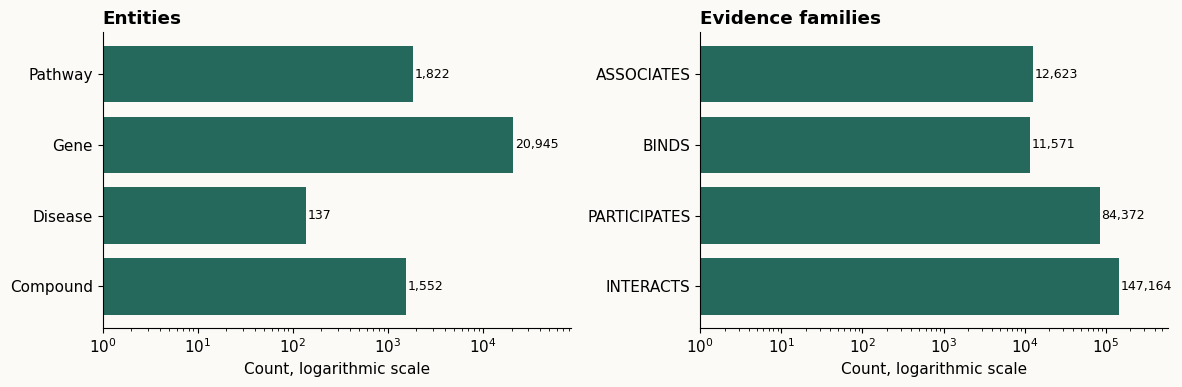

In [2]:
stats = engine.stats()
assert set(stats["edge_counts"]) == {"BINDS", "ASSOCIATES", "INTERACTS", "PARTICIPATES"}
assert stats["treatment_labels"] == 755
print(f"{stats['nodes']:,} nodes · {stats['edges']:,} evidence edges · {stats['treatment_labels']} separate treatment labels")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in zip(axes, [stats["node_counts"], stats["edge_counts"]], ["Entities", "Evidence families"]):
    names, values = list(counts), list(counts.values())
    ax.barh(names, values, color="#24695c")
    ax.set_xscale("log")
    ax.set_xlabel("Count, logarithmic scale")
    ax.set_title(title, loc="left", weight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    for index, value in enumerate(values):
        ax.text(value * 1.05, index, f"{value:,}", va="center", fontsize=9)
    ax.set_xlim(1, max(values) * 4)
fig.tight_layout()
plt.show()

## 2. A concrete investigation

Asthma is useful because the graph produces non-obvious, sometimes clinically implausible candidates. That makes it a good test of the application's honesty. We inspect the evidence and the model's limitations instead of treating a high score as medical validation.

The explorer lists compounds with at least one surviving path. The benchmark later uses **all 1,552 compounds**, including zero-path compounds.

In [3]:
disease = engine.diseases("asthma")["items"][0]
ranking = engine.rankings(disease["id"], limit=8)
rows = [{"rank": row["rank"], "compound": row["name"], "score": round(row["score"], 4),
         "direct": row["features"]["direct"], "interaction": row["features"]["interaction"],
         "pathway": row["features"]["pathway"], "known": row["known_treatment"]}
        for row in ranking["candidates"]]
table(rows, [("rank","Rank"),("compound","Compound"),("score","Relative score"),
             ("direct","Direct"),("interaction","Interaction"),("pathway","Pathway"),("known","Recorded treatment")])

| Rank | Compound | Relative score | Direct | Interaction | Pathway | Recorded treatment |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Captopril | 0.8894 | 4 | 23 | 1206 | False |
| 2 | Doxorubicin | 0.8882 | 4 | 25 | 1769 | False |
| 3 | Vitamin E | 0.88 | 5 | 27 | 3212 | False |
| 4 | Minocycline | 0.874 | 4 | 24 | 1611 | False |
| 5 | L-Citrulline | 0.8666 | 3 | 11 | 599 | False |
| 6 | Cisplatin | 0.8629 | 5 | 5 | 1340 | False |
| 7 | Ibuprofen | 0.8586 | 4 | 18 | 2371 | False |
| 8 | Carboplatin | 0.8582 | 4 | 4 | 650 | False |

## 3. Counts and explanations are different objects

The model uses exact full-graph path counts. A readable diagram shows a bounded selection. The API retains both quantities, which prevents a display limit from silently changing the scientific features.

Captopril — asthma
Exact counts: {'direct': 4, 'interaction': 23, 'pathway': 1206}
Displayed paths: 3 of 1233


| Relationship | Recorded source metadata | Available license |
| --- | --- | --- |
| PARTICIPATES | ['Reactome via Pathway Commons'] | CC BY 4.0 |
| PARTICIPATES | ['Reactome via Pathway Commons'] | CC BY 4.0 |
| ASSOCIATES | ['DisGeNET'] | ODbL 1.0 |
| BINDS | ['ChEMBL', 'DrugBank (target)', 'DrugCentral (ChEMBL)', 'DrugCentral (literature)'] | CC BY-SA 3.0 |
| ASSOCIATES | ['DisGeNET'] | ODbL 1.0 |
| ASSOCIATES | ['DOAF'] | None |
| INTERACTS | ['II_literature', 'hetio-dag'] | None |
| BINDS | ['DrugBank (enzyme)'] | CC BY-NC 4.0 |

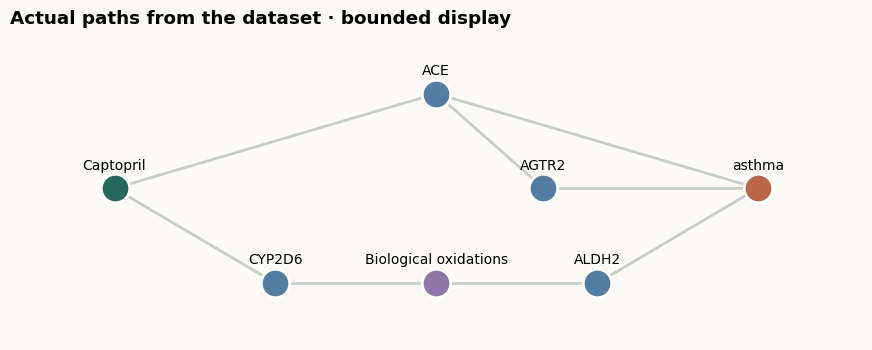

In [4]:
compound = ranking["candidates"][0]
evidence = engine.evidence(disease["id"], compound["id"], limit=3)
assert evidence["total_paths"] == sum(evidence["counts"].values())
assert evidence["truncated"] == (evidence["total_paths"] > len(evidence["paths"]))
print(f"{compound['name']} — {disease['name']}")
print("Exact counts:", evidence["counts"])
print("Displayed paths:", len(evidence["paths"]), "of", evidence["total_paths"])
table(evidence["edges"], [("type","Relationship"),("sources","Recorded source metadata"),("license","Available license")])

nodes = {node["id"]: node for node in evidence["nodes"]}
positions = {}
for index, path in enumerate(evidence["paths"]):
    for step, identifier in enumerate(path["node_ids"]):
        if identifier == compound["id"]:
            positions[identifier] = (0, 0)
        elif identifier == disease["id"]:
            positions[identifier] = (4, 0)
        else:
            positions.setdefault(identifier, (4 * step / (len(path["node_ids"]) - 1), 1 - index))
colors = {"Compound":"#24695c", "Disease":"#ba6449", "Gene":"#527ca0", "Pathway":"#8e76a6"}
fig, ax = plt.subplots(figsize=(11, 4))
for edge in evidence["edges"]:
    if edge["source"] in positions and edge["target"] in positions:
        start, end = positions[edge["source"]], positions[edge["target"]]
        ax.plot([start[0],end[0]],[start[1],end[1]], color="#c7cec8", linewidth=2, zorder=1)
for identifier, (x, y) in positions.items():
    node=nodes[identifier]
    ax.scatter(x, y, s=420, color=colors[node["label"]], edgecolors="white", linewidth=2, zorder=3)
    ax.text(x,y+0.17,node["name"],ha="center",va="bottom",fontsize=10)
ax.set_xlim(-.65,4.65)
ax.set_ylim(-1.6,1.65)
ax.axis("off")
ax.set_title("Actual paths from the dataset · bounded display",loc="left",weight="bold")
plt.show()

## 4. Challenge the evidence

Removing interaction edges changes the feature vector while holding the scaler and model coefficients fixed. A compound can rise because its competitors lose more support. This operation tests evidence sensitivity, not the effect of changing a cell or patient.

In [5]:
model_before = json.dumps(engine.model, sort_keys=True)
challenge = engine.challenge(disease["id"], ["INTERACTS"], limit=5)
assert model_before == json.dumps(engine.model, sort_keys=True)
assert all(row["features"]["interaction"] == 0 for row in challenge["after"])
table(challenge["changes"], [("name","Compound"),("before_rank","Before"),("after_rank","After"),
                              ("rank_delta","Rank gain"),("score_before","Score before"),("score_after","Score after")])
print(challenge["explanation"])

| Compound | Before | After | Rank gain | Score before | Score after |
| --- | --- | --- | --- | --- | --- |
| Captopril | 1 | 3 | -2 | 0.88940684 | 0.62665237 |
| Doxorubicin | 2 | 19 | -17 | 0.88820159 | 0.54566911 |
| Vitamin E | 3 | 14 | -11 | 0.87996462 | 0.55862127 |
| Minocycline | 4 | 9 | -5 | 0.87403393 | 0.59122826 |
| L-Citrulline | 5 | 6 | -1 | 0.8666036 | 0.60342674 |
| Carboplatin | 8 | 1 | 7 | 0.85820882 | 0.67607623 |
| Cisplatin | 6 | 2 | 4 | 0.86285595 | 0.65321819 |
| Oxaliplatin | 14 | 4 | 10 | 0.82535503 | 0.61461083 |
| Roflumilast | 50 | 5 | 45 | 0.75833678 | 0.61254021 |

Removed relationship families change exact path features while the trained scaler and coefficients remain fixed. Rank increases can follow competitors losing evidence. This is evidence sensitivity, not a biological intervention.


## 5. Reconstruct the selected compound score (version 1.1)

Follow **Nicotine → Alzheimer's disease** while removing only `INTERACTS`. The assessment keeps the compound fixed even when its ranking changes. The fitted model, scaler and all eight feature definitions remain unchanged.

For transformed feature $x_j$, training mean $\mu_j$, training scale $s_j$ and coefficient $\beta_j$, the signed term is $c_j=\beta_j(x_j-\mu_j)/s_j$. The intercept and terms reconstruct the logit, and the sigmoid reconstructs the retrieval score:

$$z=\beta_0+\sum_j c_j, \qquad \operatorname{score}=\frac{1}{1+e^{-z}}.$$

The table below shows all eight terms before and after exclusion. Calculations and assertions use full precision; displayed values are rounded. The reference point is the training-feature mean, so an absent feature can still have a nonzero signed contribution. Terms add in **logit space**, not score space. This explains the fitted model's arithmetic; it is neither a causal biological attribution nor a clinical probability.

In [6]:
nicotine = engine.assessment("Disease::DOID:10652", "Compound::DB00184", ["INTERACTS"])
terms = nicotine["decomposition"]["features"]
intercept = nicotine["decomposition"]["intercept"]
assert len(terms) == 8
assert [term["name"] for term in terms] == engine.model["feature_names"]
assert nicotine["model"]["model_sha256"] == engine.model["model_sha256"]
assert json.dumps(engine.model, sort_keys=True) == model_before
assert (nicotine["baseline"]["rank"], nicotine["current"]["rank"]) == (2, 10)
assert nicotine["current"]["features"]["interaction"] == 0

for state, suffix in [("baseline", "before"), ("current", "after")]:
    for term in terms:
        reconstructed_term = term["coefficient"] * (term[f"value_{suffix}"] - term["mean"]) / term["scale"]
        assert np.isclose(reconstructed_term, term[f"contribution_{suffix}"], atol=1e-12, rtol=0)
    reconstructed_logit = intercept + sum(term[f"contribution_{suffix}"] for term in terms)
    reconstructed_score = 1 / (1 + np.exp(-reconstructed_logit))
    assert np.isclose(reconstructed_logit, nicotine[state]["logit"], atol=1e-12, rtol=0)
    assert np.isclose(reconstructed_score, nicotine[state]["score"], atol=1e-12, rtol=0)

assert np.isclose(sum(term["contribution_delta"] for term in terms),
                  nicotine["delta"]["logit"], atol=1e-12, rtol=0)
assert np.isclose(nicotine["current"]["score"] - nicotine["baseline"]["score"],
                  nicotine["delta"]["score"], atol=1e-12, rtol=0)

table([{"scenario": label, "rank": nicotine[state]["rank"],
        "score": round(nicotine[state]["score"], 6), "logit": round(nicotine[state]["logit"], 6),
        "paths": nicotine[state]["evidence_count"]}
       for state, label in [("baseline", "All evidence"), ("current", "INTERACTS excluded")]],
      [("scenario", "Scenario"), ("rank", "Supported rank"), ("score", "Retrieval score"),
       ("logit", "Logit"), ("paths", "Supporting paths")])

table([{"feature": term["name"], "value_before": round(term["value_before"], 5),
        "value_after": round(term["value_after"], 5), "coefficient": round(term["coefficient"], 5),
        "before": round(term["contribution_before"], 5), "after": round(term["contribution_after"], 5),
        "delta": round(term["contribution_delta"], 5)} for term in terms],
      [("feature", "Feature"), ("value_before", "Value before"), ("value_after", "Value after"),
       ("coefficient", "Coefficient"), ("before", "Term before"), ("after", "Term after"),
       ("delta", "Term change")])
print(f"Saved intercept: {intercept:.8f}")
print(f"Rank: 2 → 10; rank gain: {nicotine['delta']['rank']}")
print(f"Logit change: {nicotine['delta']['logit']:.8f}; score change: {nicotine['delta']['score']:.8f}")
print("All eight terms reconstruct both logits and scores within 1e-12.")

unsupported = engine.assessment("Disease::DOID:10652", "Compound::DB00184", ["BINDS"])
assert unsupported["current"]["rank"] is None and not unsupported["current"]["supported"]
assert unsupported["current"]["evidence_count"] == 0
assert unsupported["current"]["score_status"] == "unsupported_diagnostic"
assert np.isfinite(unsupported["current"]["score"])
print("Removing BINDS retains the pair with zero paths, no supported rank, and an explicitly diagnostic score.")
print("These are model-sensitivity calculations, not treatment recommendations or causal effects.")

| Scenario | Supported rank | Retrieval score | Logit | Supporting paths |
| --- | --- | --- | --- | --- |
| All evidence | 2 | 0.921462 | 2.462383 | 1997 |
| INTERACTS excluded | 10 | 0.679738 | 0.752566 | 1982 |

| Feature | Value before | Value after | Coefficient | Term before | Term after | Term change |
| --- | --- | --- | --- | --- | --- | --- |
| log_direct | 1.94591 | 1.94591 | 0.32281 | 1.03177 | 1.03177 | 0.0 |
| log_interaction | 2.77259 | 0.0 | 0.88684 | 1.3204 | -0.76128 | -2.08168 |
| log_pathway | 7.58934 | 7.58934 | 4.02849 | 4.59528 | 4.59528 | 0.0 |
| normalized_direct | 0.07303 | 0.07303 | 0.31687 | 0.88556 | 0.88556 | 0.0 |
| normalized_interaction | 0.17345 | 0.0 | -0.34612 | -0.16621 | 0.20565 | 0.37187 |
| normalized_pathway | 3.2562 | 3.2562 | -2.66999 | -2.74287 | -2.74287 | 0.0 |
| log_compound_degree | 3.49651 | 3.49651 | -0.81842 | -1.50609 | -1.50609 | 0.0 |
| log_disease_degree | 5.2832 | 5.2832 | -1.37998 | -0.36512 | -0.36512 | 0.0 |

Saved intercept: -0.59032941
Rank: 2 → 10; rank gain: -8
Logit change: -1.70981631; score change: -0.24172463
All eight terms reconstruct both logits and scores within 1e-12.


Removing BINDS retains the pair with zero paths, no supported rank, and an explicitly diagnostic score.
These are model-sensitivity calculations, not treatment recommendations or causal effects.


## 6. Evaluate against the full candidate universe

The task is retrospective recovery of recorded treatment links. The split is at the compound–disease pair level, so this is a transductive experiment. Training and validation positives are masked for each test disease. Other test positives remain in the ranking.

The logistic model selects regularization using validation MRR. The test results below are read from the executed experiment, with uncertainty estimated by resampling disease clusters.

Split: {'train': 528, 'validation': 113, 'test': 114, 'unobserved_train': 5280}
Candidate universe: All 1,552 compounds, including compounds with no paths; mask train and validation positives for each test disease


| Method | Recall@10 | MRR | Hits | Held-out links |
| --- | --- | --- | --- | --- |
| Typed-path logistic | 0.0965 | 0.0439 | 11 | 114 |
| Path count baseline | 0.0088 | 0.0069 | 1 | 114 |
| Target-degree baseline | 0.0088 | 0.0072 | 1 | 114 |
| Direct-overlap baseline | 0.0526 | 0.0365 | 6 | 114 |

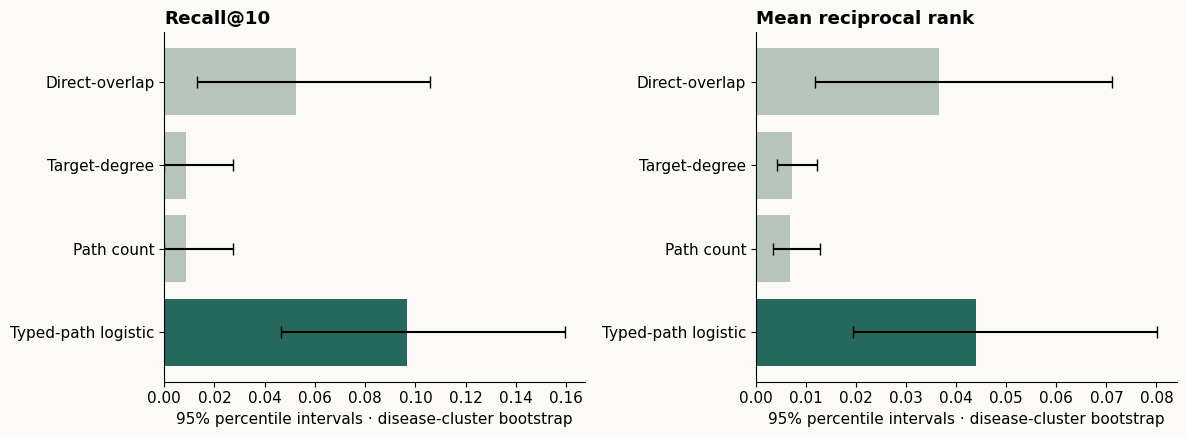

In [7]:
print("Split:", {key: report["split"][key] for key in ["train","validation","test","unobserved_train"]})
print("Candidate universe:", report["protocol"]["candidate_universe"])
metrics = report["metrics"]
table([{**row, "recall_at_10": round(row["recall_at_10"], 4), "mrr": round(row["mrr"], 4)} for row in metrics],
      [("model","Method"),("recall_at_10","Recall@10"),("mrr","MRR"),("hits_at_10","Hits"),("evaluated_links","Held-out links")])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ["recall_at_10","mrr"], ["Recall@10", "Mean reciprocal rank"]):
    values = np.array([row[metric] for row in metrics])
    intervals = np.array([row[metric + "_ci95"] for row in metrics])
    errors = np.vstack([values-intervals[:,0], intervals[:,1]-values])
    ax.barh([row["model"].replace(" baseline", "") for row in metrics], values,
            xerr=errors, capsize=4, color=["#24695c", "#b6c4bb", "#b6c4bb", "#b6c4bb"])
    ax.set_title(title,loc="left",weight="bold")
    ax.spines[["top","right"]].set_visible(False)
    ax.set_xlabel("95% percentile intervals · disease-cluster bootstrap")
fig.tight_layout()
Path("reports").mkdir(exist_ok=True)
fig.savefig("reports/benchmark.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Show a success and the failures

The first, median and worst held-out ranks make the limitations tangible. A single successful example cannot replace the full experiment. Many pathways do not guarantee a useful rank, and a useful rank does not establish therapeutic benefit.

In [8]:
table(report["examples"], [("compound","Compound"),("disease","Recorded indication"),
                           ("rank","Held-out rank"),("candidate_count","Candidates"),("outcome","Outcome")])
for limitation in report["limitations"]:
    print("•", limitation)

| Compound | Recorded indication | Held-out rank | Candidates | Outcome |
| --- | --- | --- | --- | --- |
| Dextrothyroxine | hypothyroidism | 1 | 1550 | recovered_in_top_10 |
| Loratadine | allergic rhinitis | 207 | 1541 | missed_top_10 |
| Apraclonidine | glaucoma | 1271 | 1535 | missed_top_10 |

• Retrospective recovery is not clinical efficacy validation or new drug discovery.
• The evidence graph is historical and transductive; this is not a temporal or unseen-disease generalization test.
• Removing indication edges prevents direct graph leakage, but correlated literature curation can still encode prior medical knowledge.
• Unobserved pairs can contain real but undocumented treatments; retrieval scores are not calibrated probabilities.
• A single fixed split has sampling uncertainty. All test links and failures are retained in the report.
• Dense well-studied biology receives more coverage. Source relationships are consolidated observations, not independent studies.
• Evidence-family ablation measures model sensitivity, not causal biological interventions.
• Binding and association edges do not encode beneficial action direction, dose, safety, contraindications, or tissue specificity. High-ranking compounds can be medically inappropriate.


## 8. Inspect the graph algorithm separately

Personalized PageRank measures graph proximity to the selected disease. It is a separate analysis signal. This notebook's execution backend is explicitly reported as SciPy. The deployed Neo4j endpoint runs the corresponding GDS algorithm and the integration test verifies that path.

In [9]:
algorithm = engine.algorithms(disease["id"], limit=5)
print("Algorithm:", algorithm["algorithm"])
print("Execution backend:", algorithm["execution_backend"])
table(algorithm["items"], [("name","Compound"),("score","Graph proximity")])

Algorithm: Personalized PageRank
Execution backend: scipy-power-iteration


| Compound | Graph proximity |
| --- | --- |
| Pranlukast | 0.00018131739702071233 |
| Glutathione | 0.00016347827204196724 |
| Sunitinib | 0.00013941908370359335 |
| Marimastat | 0.00012065842634071249 |
| Melatonin | 0.00011945952723810289 |

## What this experiment establishes

The application can reproduce a recorded graph, trace evidence, change that evidence under a fixed scoring model, and measure held-out retrieval against transparent baselines. The model improves on these baselines on this split while retaining substantial failure modes.

It does not establish causal mechanisms, clinical safety, novel drug discovery or generalization to unseen diseases. Those would require different data and evaluation designs. The next scientific question is whether the observed advantage survives disease-disjoint or temporally separated evaluation, not whether a more elaborate explanation can make the current score sound stronger.

Sources: [Hetionet repository](https://github.com/hetio/hetionet), [original paper](https://doi.org/10.7554/eLife.26726), [model card](docs/model_card.md).